# Entanglement and the Bell states

Two qubits can each hold their own state: qubit 1 in $|0\rangle$ and qubit 0
in $|+\rangle$, say. Is every state of two qubits made that way, out of one
state per qubit? The answer is no, and the states that are not made that way
are what give quantum computers much of their power.

This notebook builds such states with two gates you already know: the
classical CX from Notebook 02 and one Hadamard from Notebook 04. It then
answers a practical question. Given only measurement results, and noisy ones
from real hardware, how can you prove that two qubits are in one of these
states and not in something an ordinary random process could imitate?

## Before you start

This notebook uses:

- the tensor product and Qiskit's bit order, with qubit 0 on the right
  ([Notebook 00](00_Bits_and_Basis_States.ipynb));
- CX (control and target) and the subscript notation $A_k$ for an operator on
  qubit $k$ ([Notebook 02](02_Reversible_Logic.ipynb));
- amplitudes, the Born rule, the Hadamard $H$, the states $|\pm\rangle$, the
  Pauli $Y$, and Qiskit's `Statevector`
  ([Notebook 04](04_Amplitudes_and_Phase.ipynb));
- the barrier and the change of basis, in particular the X-basis
  measurement: apply $H$, then measure in the Z basis
  ([Notebook 06](06_Interference_H_vs_SX.ipynb));
- Pauli strings, Qiskit's label order, and `SparsePauliOp`
  ([Notebook 08](08_Pauli_Sums.ipynb));
- expectation values $\langle O\rangle$, standard errors, and the Estimator
  with its `precision` setting ([Notebook 09](09_Sampler_vs_Estimator.ipynb)).

Quick check:

1. Write $|0\rangle \otimes |+\rangle$ as a four-component vector. (Qiskit
   order: the left factor is qubit 1.)
2. What does CX with control qubit 0 and target qubit 1 do to $|01\rangle$?
3. What is $\langle Z\rangle$ for the state $|+\rangle$?

Answers: $(1, 1, 0, 0)^T/\sqrt2$; it returns $|11\rangle$, because bit 0 is 1
and so bit 1 flips; $\langle Z\rangle = P(0) - P(1) = 1/2 - 1/2 = 0$.

After this notebook you will be able to:

1. Decide whether a given two-qubit state can be written as (state of
   qubit 1) $\otimes$ (state of qubit 0).
2. Predict the Z-basis and X-basis counts of the four states made by an $H$
   on qubit 0 followed by a CX.
3. Compute the averages $\langle Z_1Z_0\rangle$, $\langle X_1X_0\rangle$ and
   $\langle Y_1Y_0\rangle$ of a two-qubit state, and use their size to show,
   from noisy data, that the state cannot be written as one state per qubit.
4. Explain why two qubits that always give the same Z-basis result need not
   be in such a state.

## Setup

This cell loads the libraries and decides where circuits run. By default it
uses only the simulator; the hardware exercises at the end change that.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit (Sampler jobs)
    precision=0.02,              # target standard error (Estimator jobs)
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Product states

The simplest way to describe two qubits is to give each one its own state.
If qubit 1 is in $|\psi_1\rangle$ and qubit 0 is in $|\psi_0\rangle$, the
pair is in $|\psi_1\rangle \otimes |\psi_0\rangle$, the tensor product from
Notebook 00 with qubit 1 as the left factor.

A *product state* is a two-qubit state that can be written as
$|\psi_1\rangle \otimes |\psi_0\rangle$ for some one-qubit states
$|\psi_1\rangle$ and $|\psi_0\rangle$. In words: a product state is fully
described by listing the state of each qubit on its own.

Every bitstring is a product state: $|10\rangle = |1\rangle \otimes |0\rangle$.
So is $|{+}{+}\rangle = |+\rangle \otimes |+\rangle$, which works out to
$(|00\rangle + |01\rangle + |10\rangle + |11\rangle)/2$, an equal
superposition of all four bitstrings. Labels such as $|0{+}\rangle$ follow the
same Qiskit order as bitstrings: in $|0{+}\rangle$, qubit 1 is $|0\rangle$ and
qubit 0 is $|+\rangle$.

Every state in Notebooks 00 to 03 was a product state, because the operators
there map bitstrings to bitstrings. A one-qubit gate acting on one qubit of a
product state also leaves a product state, because it changes only that
qubit's factor.

**Check.** Write $|0{+}\rangle$ as a combination of the four bitstrings.

## A state that is not a product state

Put the two ingredients together. Start in $|00\rangle$, apply $H$ to qubit 0,
then apply CX with qubit 0 as control and qubit 1 as target.

### Example 1: the output of $H$ then CX

**Problem.** Compute the state $\mathrm{CX}\,H_0\,|00\rangle$.

**Plan.** Apply the gates one at a time, right to left. Use linearity: an
operator acting on a sum acts on each term.

**Solution.**

**Subgoal 1: apply $H$ to qubit 0.**

1. Write $|00\rangle = |0\rangle \otimes |0\rangle$. $H_0$ changes only the
   right factor.
2. Use $H|0\rangle = |+\rangle = (|0\rangle + |1\rangle)/\sqrt2$:
   $H_0|00\rangle = |0\rangle \otimes (|0\rangle + |1\rangle)/\sqrt2$.
3. Multiply out the tensor product:
   $H_0|00\rangle = (|00\rangle + |01\rangle)/\sqrt2$.

**Subgoal 2: apply CX.**

4. By linearity, CX acts on each bitstring separately.
5. In $|00\rangle$ the control bit 0 is 0, so nothing flips: $|00\rangle$.
6. In $|01\rangle$ the control bit 0 is 1, so bit 1 flips: $|11\rangle$.
7. Add the results: $\mathrm{CX}\,H_0\,|00\rangle = (|00\rangle + |11\rangle)/\sqrt2$.

**Check.** The squared amplitudes are $1/2 + 1/2 = 1$, so the state is
normalized. A Z-basis measurement returns 00 or 11, each half the time, and
never 01 or 10: the two bits always agree.

**Takeaway.** CX copies the value of bit 0 into bit 1 for each bitstring in
the superposition, so the two bits end up always equal.

Can $(|00\rangle + |11\rangle)/\sqrt2$ be written as a product state? Try it.

### Example 2: $(|00\rangle + |11\rangle)/\sqrt2$ is not a product state

**Problem.** Show that no one-qubit states $|\psi_1\rangle = b_0|0\rangle + b_1|1\rangle$
and $|\psi_0\rangle = a_0|0\rangle + a_1|1\rangle$ satisfy
$|\psi_1\rangle \otimes |\psi_0\rangle = (|00\rangle + |11\rangle)/\sqrt2$.

**Plan.** Multiply out the general product, match amplitudes term by term, and
show the resulting equations contradict each other.

**Solution.**

**Subgoal 1: write the general product state.**

1. Multiply out the tensor product, keeping the qubit-1 factor on the left:
   $|\psi_1\rangle \otimes |\psi_0\rangle = b_0a_0|00\rangle + b_0a_1|01\rangle + b_1a_0|10\rangle + b_1a_1|11\rangle$.

**Subgoal 2: match amplitudes.**

2. The target has amplitude $1/\sqrt2$ on $|00\rangle$ and $|11\rangle$ and
   0 on the others, so we need $b_0a_0 = 1/\sqrt2$, $b_1a_1 = 1/\sqrt2$,
   $b_0a_1 = 0$ and $b_1a_0 = 0$.
3. A product of two numbers is zero only if one of them is zero. From
   $b_0a_1 = 0$, either $b_0 = 0$ or $a_1 = 0$.
4. If $b_0 = 0$, then $b_0a_0 = 0$, which contradicts $b_0a_0 = 1/\sqrt2$.
5. If $a_1 = 0$, then $b_1a_1 = 0$, which contradicts $b_1a_1 = 1/\sqrt2$.

**Check.** Both cases fail, so no choice of the four amplitudes works. The
same test passes for a real product: $|{+}{+}\rangle$ has all four amplitudes
$1/2$, and $b_0 = b_1 = a_0 = a_1 = 1/\sqrt2$ gives it.

**Self-explanation prompt.** The contradiction starts at step 3. What property
of the target state does that step use? **Answer.** That the target has a zero
amplitude on $|01\rangle$ while both $|00\rangle$ and $|11\rangle$ have nonzero
amplitudes. A product state with a zero on $|01\rangle$ must lose $|00\rangle$
or $|11\rangle$ as well.

**Takeaway.** A two-qubit state is a product state only if its four
amplitudes can be written as $b_ja_k$; checking this is a finite set of
equations.

An *entangled state* is a two-qubit state that is not a product state. In
words: no description that gives each qubit its own state can reproduce it.
The state of Example 2 is entangled.

Look at what made it. CX is the classical reversible gate of Notebook 02; on
its own it maps bitstrings to bitstrings, which are product states. $H$ acts on
one qubit, so on its own it also keeps product states. The entanglement comes
from applying CX to a superposition, which only the quantum ingredient of
Notebook 04 provides.

**Check.** Is $\mathrm{CX}|10\rangle$ entangled?

## The four Bell states

The *Bell states* are four entangled states of two qubits:

$$|\Phi^\pm\rangle = \tfrac{1}{\sqrt2}\big(|00\rangle \pm |11\rangle\big),
\qquad
|\Psi^\pm\rangle = \tfrac{1}{\sqrt2}\big(|01\rangle \pm |10\rangle\big).$$

In words: in $\Phi^\pm$ the two bits always agree, in $\Psi^\pm$ they always
differ, and the sign between the two terms is a relative phase (Notebook 04).

The circuit of Example 1 makes all four. Set the input bitstring with NOT
gates first, then apply $H_0$ and CX. Repeating Example 1 for each input gives
the table below; the code cell after it checks it with `Statevector`.

| input $\lvert x_1x_0\rangle$ | output |
|---|---|
| $\lvert 00\rangle$ | $\lvert\Phi^+\rangle$ |
| $\lvert 01\rangle$ | $\lvert\Phi^-\rangle$ |
| $\lvert 10\rangle$ | $\lvert\Psi^+\rangle$ |
| $\lvert 11\rangle$ | $-\lvert\Psi^-\rangle$, which is $\lvert\Psi^-\rangle$ up to a global phase |

**Warning.** The input labels are bitstrings in Qiskit order. The input
$|01\rangle$ means qubit 0 starts as 1 and qubit 1 as 0.

amplitudes of |00>, |01>, |10>, |11> (all real here):
  Phi+  +0.707  +0.000  +0.000  +0.707
  Phi-  +0.707  +0.000  +0.000  -0.707
  Psi+  +0.000  +0.707  +0.707  +0.000
  Psi-  +0.000  -0.707  +0.707  +0.000


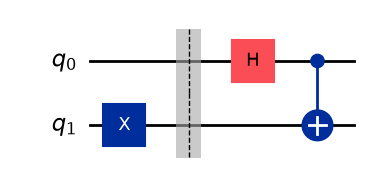

In [2]:
BELL_INPUT = {"Phi+": "00", "Phi-": "01", "Psi+": "10", "Psi-": "11"}


def build_state(name):
    """Return a two-qubit circuit (no measurement) that prepares the named state."""
    qubits = QuantumRegister(2, name="q")
    circuit = QuantumCircuit(qubits, name=name)
    if name in BELL_INPUT:
        input_bits = BELL_INPUT[name]
        for k in range(2):
            if input_bits[-1 - k] == "1":
                circuit.x(qubits[k])
        circuit.barrier()
        circuit.h(qubits[0])               # the only non-classical gate
        circuit.cx(qubits[0], qubits[1])   # classical reversible XOR
    elif name == "|11>":
        circuit.x(qubits)
    elif name == "|++>":
        circuit.h(qubits)
    elif name == "|0+>":
        circuit.h(qubits[0])
    elif name != "|00>":
        raise ValueError(f"Unknown state {name!r}")
    return circuit


names = list(BELL_INPUT) + ["|00>", "|11>", "|++>", "|0+>"]
states = {n: build_state(n) for n in names}

print("amplitudes of |00>, |01>, |10>, |11> (all real here):")
for name in BELL_INPUT:
    amplitudes = Statevector(states[name]).data.real
    print(f"  {name:5s} " + "  ".join(f"{v:+.3f}" for v in amplitudes))
states["Psi+"].draw("mpl")

The printed amplitudes match the table: $0.707 \approx 1/\sqrt2$, and the
input $|11\rangle$ gives $-0.707$ on $|01\rangle$ and $+0.707$ on $|10\rangle$,
which is $-|\Psi^-\rangle$.

$|\Phi^+\rangle$ and $|\Phi^-\rangle$ give the same Z-basis counts, 00 and 11
half the time each, because the Born rule squares away the sign. They differ
in the X basis.

### Example 3: $\Phi^+$ and $\Phi^-$ in the X basis

**Problem.** Predict the X-basis counts of $|\Phi^+\rangle$ and $|\Phi^-\rangle$.

**Plan.** An X-basis measurement of both qubits is $H$ on each qubit followed
by a Z-basis measurement (Notebook 06). Compute $H_1H_0$ on $|00\rangle$ and
$|11\rangle$, then combine.

**Solution.**

**Subgoal 1: $H$ on both qubits of each bitstring.**

1. $H_1H_0|00\rangle = |+\rangle \otimes |+\rangle = \tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle)$.
2. $H_1H_0|11\rangle = |-\rangle \otimes |-\rangle$. Multiply out
   $(|0\rangle - |1\rangle)(|0\rangle - |1\rangle)/2$:
   $\tfrac12(|00\rangle - |01\rangle - |10\rangle + |11\rangle)$.

**Subgoal 2: combine with the sign of each Bell state.**

3. For $\Phi^+$, add the two lines and divide by $\sqrt2$. The $|01\rangle$ and
   $|10\rangle$ terms cancel: $H_1H_0|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$.
4. For $\Phi^-$, subtract the second line from the first. Now $|00\rangle$ and
   $|11\rangle$ cancel: $H_1H_0|\Phi^-\rangle = (|01\rangle + |10\rangle)/\sqrt2$.

**Check.** Both results are normalized. In the X basis, $\Phi^+$ gives only 00
and 11, and $\Phi^-$ gives only 01 and 10: completely different counts.

**Takeaway.** The relative sign that the Z basis cannot see decides which
outcomes interfere away in the X basis.

**Check.** Which X-basis outcomes do you expect for $|{+}{+}\rangle$?

## Correlators

Counts in two bases already separate the Bell states. To prove entanglement
from data, it is better to boil the counts down to a few numbers.

A *correlator* is the expectation value of the same Pauli operator on both
qubits: $\langle Z_1Z_0\rangle$, $\langle X_1X_0\rangle$ or
$\langle Y_1Y_0\rangle$, written $\langle ZZ\rangle$, $\langle XX\rangle$ and
$\langle YY\rangle$ for short. As Qiskit Pauli strings they are `"ZZ"`,
`"XX"` and `"YY"`; the two letters are equal, so the label order does not
matter here.

In words, for $\langle ZZ\rangle$: the operator $Z_1Z_0$ has eigenvalue $+1$
on $|00\rangle$ and $|11\rangle$ and $-1$ on $|01\rangle$ and $|10\rangle$.
Each bitstring has the probability given by the Born rule for several qubits
(Notebook 04), and the probability of the outcome $+1$ is the sum of the
probabilities of the two bitstrings that give it. So

$$\langle ZZ\rangle = P(\text{bits agree}) - P(\text{bits differ}).$$

It ranges from $+1$ (always agree) to $-1$ (always differ). $\langle XX\rangle$
is the same thing for the X-basis results.

### Example 4: two correlators of the Bell states

**Problem.** Compute $\langle XX\rangle$ for $|\Phi^-\rangle$ and
$\langle YY\rangle$ for $|\Phi^+\rangle$.

**Plan.** Apply the operator to the state. If the result is $\pm$ the state,
the expectation value is that sign, because $\langle\psi|(\pm|\psi\rangle) = \pm1$
for a normalized state.

**Solution.**

**Subgoal 1: $X_1X_0$ on $|\Phi^-\rangle$.**

1. $X_1X_0$ flips both bits: $|00\rangle \to |11\rangle$ and $|11\rangle \to |00\rangle$.
2. So $X_1X_0(|00\rangle - |11\rangle)/\sqrt2 = (|11\rangle - |00\rangle)/\sqrt2 = -|\Phi^-\rangle$.
3. Therefore $\langle XX\rangle = -1$.

**Subgoal 2: $Y_1Y_0$ on $|\Phi^+\rangle$.**

4. From Notebook 04, $Y|0\rangle = i|1\rangle$ and $Y|1\rangle = -i|0\rangle$.
5. $Y_1Y_0|00\rangle = (i|1\rangle)\otimes(i|1\rangle) = i^2|11\rangle = -|11\rangle$.
6. $Y_1Y_0|11\rangle = (-i|0\rangle)\otimes(-i|0\rangle) = (-i)^2|00\rangle = -|00\rangle$.
7. Add: $Y_1Y_0|\Phi^+\rangle = -(|11\rangle + |00\rangle)/\sqrt2 = -|\Phi^+\rangle$, so
   $\langle YY\rangle = -1$.

**Check.** Run the code cell below: it computes all three correlators of
every state with `Statevector.expectation_value`.

**Takeaway.** Each Bell state is an eigenvector of $ZZ$, $XX$ and $YY$ at
once, so all three correlators are $\pm1$.

In [3]:
observables = [SparsePauliOp(p) for p in ("ZZ", "XX", "YY")]

print(f"{'state':6s}   <ZZ>   <XX>   <YY>")
for name, circuit in states.items():
    ideal = Statevector(circuit)
    values = [ideal.expectation_value(o).real for o in observables]
    print(f"{name:6s} " + " ".join(f"{v:+6.2f}" for v in values))

state    <ZZ>   <XX>   <YY>
Phi+    +1.00  +1.00  -1.00
Phi-    +1.00  -1.00  +1.00
Psi+    -1.00  +1.00  +1.00
Psi-    -1.00  -1.00  -1.00
|00>    +1.00  +0.00  +0.00
|11>    +1.00  +0.00  +0.00
|++>    +0.00  +1.00  +0.00
|0+>    +0.00  +0.00  +0.00


The table of ideal correlators:

| state | $\langle ZZ\rangle$ | $\langle XX\rangle$ | $\langle YY\rangle$ |
|---|---|---|---|
| $\Phi^+$ | $+1$ | $+1$ | $-1$ |
| $\Phi^-$ | $+1$ | $-1$ | $+1$ |
| $\Psi^+$ | $-1$ | $+1$ | $+1$ |
| $\Psi^-$ | $-1$ | $-1$ | $-1$ |
| $\lvert 00\rangle$, $\lvert 11\rangle$ | $+1$ | 0 | 0 |
| $\lvert{+}{+}\rangle$ | 0 | $+1$ | 0 |
| $\lvert 0{+}\rangle$ | 0 | 0 | 0 |

The product states have at most one correlator of size 1. The next two
sections show that this is no accident.

**Check.** Explain from the definition why $\langle ZZ\rangle = 1$ for
$|11\rangle$.

## The Bloch vector of one qubit

To bound the correlators of a product state, we first need a fact about one
qubit on its own.

The *Bloch vector* of a one-qubit state is
$\mathbf r = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$. In words:
the three expectation values, one per Pauli operator, stacked into a vector.
For $|0\rangle$ it is $(0, 0, 1)$, the north pole of the Bloch sphere of
Notebook 04, and for $|+\rangle$ it is $(1, 0, 0)$, the point on the $+x$
axis. Example 5 shows that this holds for every state: the Bloch vector is the
state's point on the sphere, so it points from the center of the sphere to
that point and has length 1.

### Example 5: the Bloch vector is the state's point on the sphere

**Problem.** For $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ with
$|\alpha|^2 + |\beta|^2 = 1$, show that
$\langle X\rangle^2 + \langle Y\rangle^2 + \langle Z\rangle^2 = 1$. Then show
that for the Bloch-sphere form of Notebook 04,
$\alpha = \cos(\theta/2)$ and $\beta = e^{i\varphi}\sin(\theta/2)$, the
Bloch vector is $(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$.

**Plan.** Compute each expectation value as $\langle\psi|P|\psi\rangle$ in
terms of $\alpha$ and $\beta$, add the squares, then substitute the
Bloch-sphere form.

**Solution.**

**Subgoal 1: the three expectation values.**

1. $Z|\psi\rangle = \alpha|0\rangle - \beta|1\rangle$, so
   $\langle Z\rangle = \bar\alpha\alpha - \bar\beta\beta = |\alpha|^2 - |\beta|^2$.
2. $X|\psi\rangle = \beta|0\rangle + \alpha|1\rangle$, so
   $\langle X\rangle = \bar\alpha\beta + \bar\beta\alpha$. The two terms are
   complex conjugates of each other, so their sum is twice the real part:
   $\langle X\rangle = 2\,\mathrm{Re}(\bar\alpha\beta)$.
3. $Y|\psi\rangle = -i\beta|0\rangle + i\alpha|1\rangle$, so
   $\langle Y\rangle = -i\bar\alpha\beta + i\bar\beta\alpha$. Writing
   $w = \bar\alpha\beta$, this is $-i(w - \bar w) = -i(2i\,\mathrm{Im}\,w)$, so
   $\langle Y\rangle = 2\,\mathrm{Im}(\bar\alpha\beta)$.

**Subgoal 2: add the squares.**

4. $\langle X\rangle^2 + \langle Y\rangle^2 = 4\big[(\mathrm{Re}\,w)^2 + (\mathrm{Im}\,w)^2\big] = 4|w|^2 = 4|\alpha|^2|\beta|^2$.
5. Add $\langle Z\rangle^2 = (|\alpha|^2 - |\beta|^2)^2$. The sum is
   $|\alpha|^4 + 2|\alpha|^2|\beta|^2 + |\beta|^4 = (|\alpha|^2 + |\beta|^2)^2$.
6. By normalization this is $1^2 = 1$.

**Subgoal 3: the direction.**

7. A global phase changes nothing here: multiplying $\alpha$ and $\beta$ by
   $e^{i\gamma}$ leaves $|\alpha|^2$, $|\beta|^2$ and $\bar\alpha\beta$
   unchanged. So use Notebook 04's form, $\alpha = \cos(\theta/2)$ and
   $\beta = e^{i\varphi}\sin(\theta/2)$.
8. Step 1 gives $\langle Z\rangle = \cos^2(\theta/2) - \sin^2(\theta/2) = \cos\theta$,
   by the double-angle formula for cosine.
9. $w = \bar\alpha\beta = e^{i\varphi}\cos(\theta/2)\sin(\theta/2) = e^{i\varphi}\,\tfrac12\sin\theta$,
   by the double-angle formula $\sin\theta = 2\sin(\theta/2)\cos(\theta/2)$.
10. Steps 2 and 3 give $\langle X\rangle = 2\,\mathrm{Re}\,w = \sin\theta\cos\varphi$
    and $\langle Y\rangle = 2\,\mathrm{Im}\,w = \sin\theta\sin\varphi$.

**Check.** For $|+\rangle$, $\alpha = \beta = 1/\sqrt2$: step 1 gives 0,
step 2 gives $2 \cdot \tfrac12 = 1$, step 3 gives 0, and $0 + 1 + 0 = 1$. For
$|{-i}\rangle$, Notebook 04 found $\theta = \pi/2$ and $\varphi = 3\pi/2$, so
step 10 gives $\mathbf r = (0, -1, 0)$, the point on the $-y$ axis, as in
Notebook 04's table.

**Takeaway.** The Bloch vector is the point $(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$
of Notebook 04, so it always has length 1. A one-qubit state can therefore
have a large average along only one axis at a time: if $\langle Z\rangle = \pm1$,
then $\langle X\rangle$ and $\langle Y\rangle$ must be 0.

## Why product states have small correlators

For a product state $|\psi_1\rangle\otimes|\psi_0\rangle$, each qubit has its
own Bloch vector: $\mathbf r_1$ for qubit 1 and $\mathbf r_0$ for qubit 0. Write
$\langle P\rangle_1 = \langle\psi_1|P|\psi_1\rangle$ for the average of $P$ on
qubit 1 alone, and $\langle P\rangle_0$ for qubit 0. The components of the
Bloch vectors carry the same subscripts: $r_{1z} = \langle Z\rangle_1$,
$r_{0x} = \langle X\rangle_0$, and so on. A correlator of a product state
splits into one average per qubit:

$$\langle P_1 P_0\rangle = \langle P\rangle_1\,\langle P\rangle_0 .$$

The reason is two rules for tensor products. The first is
$(A \otimes B)(u \otimes v) = (Au) \otimes (Bv)$ (Notebook 02). The second:
the inner product of two tensor products is the product of the inner
products, $(\langle a|\otimes\langle b|)(|c\rangle\otimes|d\rangle) = \langle a|c\rangle\,\langle b|d\rangle$.
It holds because entry $(j, k)$ of $|c\rangle\otimes|d\rangle$ is $c_jd_k$, so
the inner product is
$\sum_{j,k}\bar a_j\bar b_k\,c_jd_k = \big(\sum_j \bar a_jc_j\big)\big(\sum_k \bar b_kd_k\big)$.
Together they give
$(\langle\psi_1|\otimes\langle\psi_0|)(P\otimes P)(|\psi_1\rangle\otimes|\psi_0\rangle) = \langle\psi_1|P|\psi_1\rangle\,\langle\psi_0|P|\psi_0\rangle$.

Now add the three correlators of a product state, each in absolute value:

$$\begin{aligned}
S &= |\langle ZZ\rangle| + |\langle XX\rangle| + |\langle YY\rangle| \\
  &= |r_{1z}|\,|r_{0z}| + |r_{1x}|\,|r_{0x}| + |r_{1y}|\,|r_{0y}| && \text{(split each correlator)}\\
  &\le |\mathbf r_1|\,|\mathbf r_0| && \text{(Cauchy-Schwarz inequality)}\\
  &= 1 && \text{(Example 5)}.
\end{aligned}$$

The Cauchy-Schwarz inequality, from linear algebra, says that the dot product
of two vectors is at most the product of their lengths; here it is applied to
the vectors $(|r_{1x}|, |r_{1y}|, |r_{1z}|)$ and $(|r_{0x}|, |r_{0y}|, |r_{0z}|)$.

The number $S$ is an *entanglement witness*: a quantity computed from
measurements that cannot exceed a known bound, here 1, for any product state.
Every Bell state has $S = 3$. So if a measured $S$ is above 1 by more than its
uncertainty, the state was not a product state: it was entangled.

The witness works in one direction only. $S \le 1$ for every product state,
but $S \le 1$ does not prove that a state is a product state; Exercise 4 has
an example.

**Check.** What is $S$ for $|{+}{+}\rangle$, and does that contradict the
bound?

## Classical mixtures

Here is a way to fake perfect agreement without any entanglement. Flip a fair
coin. On heads, prepare $|00\rangle$; on tails, prepare $|11\rangle$. Then
measure. Every Z-basis shot gives 00 or 11, half the time each, exactly like
$|\Phi^+\rangle$.

A *classical mixture* is this procedure: prepare one of several states, chosen
at random with fixed probabilities, and do not record which one. In words: the
randomness is in our choice of preparation, not in any single state. Every
expectation value of a mixture is the probability-weighted average of the
expectation values of the states in it, because each shot comes from one of
them.

### Example 6: the witness on the coin-flip mixture

**Problem.** Compute $S$ for the 50/50 mixture of $|00\rangle$ and $|11\rangle$.

**Plan.** Average each correlator over the two preparations, using the table
above, then add the absolute values.

**Solution.**

1. $\langle ZZ\rangle$: both $|00\rangle$ and $|11\rangle$ give $+1$, so the
   average is $\tfrac12(1) + \tfrac12(1) = 1$.
2. $\langle XX\rangle$: both give 0, so the average is 0.
3. $\langle YY\rangle$: both give 0, so the average is 0.
4. Add: $S = 1 + 0 + 0 = 1$.

**Check.** The mixture matches $\Phi^+$ on $\langle ZZ\rangle$, as the coin
flip was designed to, but not on $\langle XX\rangle$ or $\langle YY\rangle$.
The X-basis counts in the experiment below show the same difference.

**Takeaway.** Agreement in one basis is easy to fake with classical
randomness. Agreement in all three bases at once is not.

The bound also holds for every mixture of product states. Each correlator of
the mixture is an average $\sum_j p_j c_j$ of the product states' correlators
$c_j$ with probabilities $p_j$, and by the triangle inequality
$|\sum_j p_j c_j| \le \sum_j p_j |c_j|$. Adding the three correlators,
$S_\text{mixture} \le \sum_j p_j S_j \le \sum_j p_j \cdot 1 = 1$.

A common mistake is to think that two qubits whose Z-basis results always
agree must be entangled. That is wrong: Example 6 agrees perfectly and is a
mixture of product states. The idea is tempting because perfect agreement
looks like a connection between the qubits; but the connection can be a
shared classical cause (the coin) decided before either qubit is measured.

This matters on hardware. Errors on a real device change which state it
actually prepares, but they cannot make a product state, or a mixture of
product states, give $S > 1$: the bound holds for every such state, whatever
produced it. A true $S$ above 1 therefore means the device really prepared an
entangled state. What can push a measured $S$ above the true value is the
random scatter of a finite number of shots. So we claim entanglement only
when $S$ is above 1 by more than three standard errors.

**Check.** Could any mixture of $|00\rangle$, $|01\rangle$, $|10\rangle$ and
$|11\rangle$ reach $S > 1$?

## The experiment

We prepare the four Bell states and four product states, look at their counts
in two bases with the Sampler, measure the three correlators with the
Estimator, and add the coin-flip mixture as a control.

### Encoding

The states are the circuits in `states`, built above by `build_state`: the
four Bell states from $H_0$ and CX, and the product states $|00\rangle$,
$|11\rangle$, $|{+}{+}\rangle$ and $|0{+}\rangle$. The mixture needs no circuit
of its own: it combines the results of $|00\rangle$ and $|11\rangle$, half
weight each.

### Operator

For the Sampler, `measured` adds a Z-basis measurement, or the X-basis change
of Notebook 06 ($H$ on both qubits) followed by a Z-basis measurement. For the
Estimator, the observables are the three correlators in `observables`,
defined above.

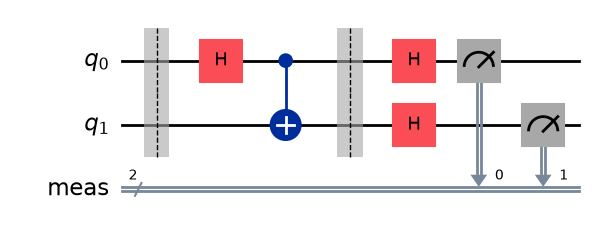

In [4]:
def measured(state, basis):
    """Return a copy of `state` that measures both qubits in the Z or X basis."""
    circuit = state.copy(name=f"{state.name}_{basis}")
    bits = ClassicalRegister(2, name="meas")
    circuit.add_register(bits)
    circuit.barrier()
    if basis == "X":
        circuit.h([0, 1])                  # change of basis: X basis -> Z basis
    circuit.measure(circuit.qubits, bits)
    return circuit


measured(states["Phi+"], "X").draw("mpl")

### Execution

**Sampler.** Each state is measured in both bases, so there are two PUBs per
state, all in one job.

In [5]:
sampler_results = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    sampler_circuits = [
        pass_manager.run(measured(c, basis))
        for c in states.values()
        for basis in ("Z", "X")
    ]
    sampler_pubs = [(isa,) for isa in sampler_circuits]
    print(f"{target.label}: {len(sampler_pubs)} Sampler PUBs in one job")
    sampler_results[target.label] = target.wait(
        target.sampler.run(sampler_pubs, shots=SETTINGS.shots)
    )

aer: 16 Sampler PUBs in one job


**Estimator.** The Estimator gets the circuits *without* measurements, because
it adds its own basis changes. The transpiler may place our qubits on other
physical qubits, so `apply_layout` rewrites each observable to act on the
same ones (Notebook 09). Notebook 09's Estimator PUB had the form
`(circuit, observable)`. The second element may also be a list of
observables, `(circuit, [O1, O2, O3])`; the Estimator then measures each one on
the same circuit, and the result's `evs` and `stds` hold one value per
observable, in the order of the list. So one PUB per state carries all three
correlators.

In [6]:
estimator_results = {}
for target in targets:
    if sampler_results[target.label] is None:
        continue  # the Sampler job failed; do not submit another
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    estimator_pubs = []
    for circuit in states.values():
        isa = pass_manager.run(circuit)
        isa_observables = [obs.apply_layout(isa.layout) for obs in observables]
        estimator_pubs.append((isa, isa_observables))
    print(f"{target.label}: {len(estimator_pubs)} Estimator PUBs in one job")
    estimator_results[target.label] = target.wait(
        target.estimator.run(estimator_pubs, precision=SETTINGS.precision)
    )

aer: 8 Estimator PUBs in one job


### Analysis

**Sampler counts.** Bitstrings read $q_1q_0$, qubit 0 on the right. The
mixture row adds the counts of $|00\rangle$ and $|11\rangle$, so it has twice
as many shots as the other rows.

In [7]:
def add_counts(first, second):
    total = dict(first)
    for key, value in second.items():
        total[key] = total.get(key, 0) + value
    return dict(sorted(total.items()))


for label, result in sampler_results.items():
    if result is None:
        continue
    print(f"Sampler counts on {label} ({SETTINGS.shots} shots per state)")
    counts = {}
    for i, name in enumerate(states):
        counts[name] = {
            "Z": result[2 * i].data.meas.get_counts(),
            "X": result[2 * i + 1].data.meas.get_counts(),
        }
    counts["mixture"] = {
        b: add_counts(counts["|00>"][b], counts["|11>"][b]) for b in ("Z", "X")
    }
    for name, by_basis in counts.items():
        print(f"  {name:8s} Z: {dict(sorted(by_basis['Z'].items()))}")
        print(f"  {'':8s} X: {dict(sorted(by_basis['X'].items()))}")

Sampler counts on aer (4096 shots per state)
  Phi+     Z: {'00': 2011, '11': 2085}
           X: {'00': 2046, '11': 2050}
  Phi-     Z: {'00': 2005, '11': 2091}
           X: {'01': 2066, '10': 2030}
  Psi+     Z: {'01': 2032, '10': 2064}
           X: {'00': 2053, '11': 2043}
  Psi-     Z: {'01': 2040, '10': 2056}
           X: {'01': 2072, '10': 2024}
  |00>     Z: {'00': 4096}
           X: {'00': 979, '01': 1051, '10': 1076, '11': 990}
  |11>     Z: {'11': 4096}
           X: {'00': 987, '01': 1079, '10': 1025, '11': 1005}
  |++>     Z: {'00': 1014, '01': 1008, '10': 1044, '11': 1030}
           X: {'00': 4096}
  |0+>     Z: {'00': 2064, '01': 2032}
           X: {'00': 2061, '10': 2035}
  mixture  Z: {'00': 4096, '11': 4096}
           X: {'00': 1966, '01': 2130, '10': 2101, '11': 1995}


On the simulator, $\Phi^+$ and $\Phi^-$ have the same Z-basis counts (only 00
and 11) and different X-basis counts (00 and 11 for $\Phi^+$, 01 and 10 for
$\Phi^-$), as Example 3 predicted. The mixture matches $\Phi^+$ in the Z basis
and spreads over all four outcomes in the X basis.

**Estimator correlators.** `evs` are the expectation values and `stds` their
standard errors. On the simulator there are no shots: the Estimator returns
the exact value plus random noise of size `precision`, so a value can land
slightly outside $[-1, 1]$. On IBM hardware, the Estimator applies some error
mitigation by default (typically readout-error mitigation) and the Sampler
applies none, so the correlators can look cleaner than the raw counts for that
reason.

The standard error of $S$ combines the three standard errors as the square
root of the sum of their squares, because the three estimates are independent
(Notebook 09). The mixture row averages the results for $|00\rangle$ and
$|11\rangle$. The average of two independent estimates with standard errors
$s_a$ and $s_b$ has standard error $\sqrt{s_a^2 + s_b^2}/2$, which is
$s/\sqrt2$ when both equal $s$; the code uses this formula.

In [8]:
def report(name, ev, std, ideal_s):
    s = np.abs(ev).sum()
    s_err = np.sqrt(np.sum(std**2))
    verdict = "entangled" if s > 1 + 3 * s_err else "no entanglement shown"
    print(f"  {name:8s} {ev[0]:+7.3f} {ev[1]:+7.3f} {ev[2]:+7.3f} "
          f"{s:6.2f} +/- {s_err:.2f} {ideal_s:8.1f}   {verdict}")


for label, result in estimator_results.items():
    if result is None:
        continue
    print(f"Estimator on {label} (precision {SETTINGS.precision})")
    print(f"  {'state':8s} {'<ZZ>':>7s} {'<XX>':>7s} {'<YY>':>7s} "
          f"{'S +/- std':>15s} {'ideal S':>8s}   verdict")
    measured_values = {}
    for (name, circuit), pub_result in zip(states.items(), result):
        ev = np.asarray(pub_result.data.evs)
        std = np.asarray(pub_result.data.stds)
        measured_values[name] = (ev, std)
        ideal = Statevector(circuit)
        ideal_s = sum(abs(ideal.expectation_value(o).real) for o in observables)
        report(name, ev, std, ideal_s)
    (ev_a, std_a), (ev_b, std_b) = measured_values["|00>"], measured_values["|11>"]
    report("mixture", (ev_a + ev_b) / 2, np.sqrt(std_a**2 + std_b**2) / 2, 1.0)

Estimator on aer (precision 0.02)
  state       <ZZ>    <XX>    <YY>       S +/- std  ideal S   verdict
  Phi+      +1.009  +1.031  -0.978   3.02 +/- 0.03      3.0   entangled


  Phi-      +0.988  -0.983  +0.952   2.92 +/- 0.03      3.0   entangled
  Psi+      -0.982  +0.993  +0.970   2.94 +/- 0.03      3.0   entangled
  Psi-      -0.991  -0.971  -1.023   2.98 +/- 0.03      3.0   entangled
  |00>      +0.969  -0.016  -0.025   1.01 +/- 0.03      1.0   no entanglement shown
  |11>      +1.033  -0.039  -0.009   1.08 +/- 0.03      1.0   no entanglement shown
  |++>      -0.007  +0.985  -0.015   1.01 +/- 0.03      1.0   no entanglement shown
  |0+>      -0.017  +0.005  +0.048   0.07 +/- 0.03      0.0   no entanglement shown
  mixture   +1.001  -0.028  -0.017   1.05 +/- 0.02      1.0   no entanglement shown


All four Bell states give $S$ near 3, far more than three standard errors
above 1. Every product state and the mixture give $S \le 1$ within noise, and
none of them is declared entangled.

## Exercises

1. Show by hand that $|\Psi^+\rangle$ is not a product state, using the method
   of Example 2.
2. Compute $\langle ZZ\rangle$, $\langle XX\rangle$ and $\langle YY\rangle$ for
   $|\Psi^+\rangle$ by hand, as in Example 4. Compare with the table.
3. Which of these two states is a product state, and which is entangled?
   (a) $\tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle)$;
   (b) $\tfrac12(|00\rangle + |01\rangle + |10\rangle - |11\rangle)$.
4. Prepare $|\Phi^+\rangle$ or $|\Phi^-\rangle$ at random, each with
   probability 1/2. Compute $S$ for this mixture. Every state in it is
   entangled; what does your answer say about what the witness can and cannot
   prove?
5. Replace the $H$ in the Bell circuit by $R_y(\theta)$ from Notebook 07, so
   the circuit is $\mathrm{CX}\,R_y(\theta)_0\,|00\rangle$. Write the output
   state, compute its three correlators as functions of $\theta$, and find
   for which $\theta$ the witness detects entanglement. Check your formula
   with `Statevector` at $\theta = 0.5$.
6. True or false: if two qubits give the same Z-basis result on every shot,
   they are entangled. Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. What is $S$ for $|\Phi^+\rangle$ on `ibm_rensselaer`, and how
   many standard errors above 1 is it? Is it closer to 3 or to 1?
8. (hardware) In the hardware Sampler counts, compare $|\Phi^+\rangle$ with the
   mixture. Can you tell them apart from the Z-basis counts alone? From the
   X-basis counts?

## What you can now do

1. Decide whether a two-qubit state is a product state by matching its
   amplitudes to $b_ja_k$.
2. Predict the Z-basis and X-basis counts of the four Bell states made by
   $H_0$ and CX.
3. Compute the correlators $\langle ZZ\rangle$, $\langle XX\rangle$,
   $\langle YY\rangle$ and use the witness $S > 1$, with a three-standard-error
   margin, to certify entanglement from noisy data.
4. Explain why perfect Z-basis agreement can come from a classical mixture,
   and why the witness is not fooled by it.

## Solutions

**Check, product states.** $|0\rangle \otimes |+\rangle = |0\rangle \otimes (|0\rangle + |1\rangle)/\sqrt2 = (|00\rangle + |01\rangle)/\sqrt2$.

**Check, entangled state.** No. Bit 0 of $|10\rangle$ is 0, so CX does
nothing and returns $|10\rangle$, a bitstring and therefore a product state.
CX entangles only when its control is in a superposition.

**Check, Bell states.** $H_1H_0|{+}{+}\rangle = |0\rangle\otimes|0\rangle$,
because $H|+\rangle = |0\rangle$. Every X-basis shot returns 00.

**Check, correlators.** In $|11\rangle$ both bits are 1, so they always agree:
$P(\text{agree}) = 1$, $P(\text{differ}) = 0$, and $\langle ZZ\rangle = 1$.

**Check, product-state bound.** For $|{+}{+}\rangle$, $S = 0 + 1 + 0 = 1$. The
bound is $S \le 1$, so a value equal to 1 is allowed. Both Bloch vectors point
along $x$, which is the case where Cauchy-Schwarz holds with equality.

**Check, mixtures.** No. Every bitstring is a product state, so every mixture
of bitstrings is a mixture of product states and has $S \le 1$.

**Exercise 1.** **Problem.** Find $b_j$, $a_k$ with
$b_0a_0|00\rangle + b_0a_1|01\rangle + b_1a_0|10\rangle + b_1a_1|11\rangle = (|01\rangle + |10\rangle)/\sqrt2$.
**Solution.** Matching amplitudes needs $b_0a_0 = 0$, $b_1a_1 = 0$,
$b_0a_1 = 1/\sqrt2$, $b_1a_0 = 1/\sqrt2$. From $b_0a_0 = 0$, either $b_0 = 0$,
which contradicts $b_0a_1 \ne 0$, or $a_0 = 0$, which contradicts
$b_1a_0 \ne 0$. **Check.** No case survives, so $|\Psi^+\rangle$ is
entangled.

**Exercise 2.** **Solution.**
1. $Z_1Z_0$ gives $-1$ on $|01\rangle$ and on $|10\rangle$, so
   $Z_1Z_0|\Psi^+\rangle = -|\Psi^+\rangle$ and $\langle ZZ\rangle = -1$.
2. $X_1X_0$ flips both bits: $|01\rangle \leftrightarrow |10\rangle$, so
   $X_1X_0|\Psi^+\rangle = |\Psi^+\rangle$ and $\langle XX\rangle = +1$.
3. $Y_1Y_0|01\rangle = (Y|0\rangle)\otimes(Y|1\rangle) = (i|1\rangle)\otimes(-i|0\rangle) = |10\rangle$,
   and in the same way $Y_1Y_0|10\rangle = (-i|0\rangle)\otimes(i|1\rangle) = |01\rangle$.
   So $Y_1Y_0|\Psi^+\rangle = |\Psi^+\rangle$ and $\langle YY\rangle = +1$.
**Check.** This matches the $\Psi^+$ row of the table: $-1, +1, +1$.

**Exercise 3.** **Solution.** (a) All four amplitudes are $1/2$; choose
$b_0 = b_1 = a_0 = a_1 = 1/\sqrt2$. It is $|{+}{+}\rangle$, a product state.
(b) We need $b_0a_0 = b_0a_1 = b_1a_0 = 1/2$ and $b_1a_1 = -1/2$. From
$b_0a_0 = b_0a_1$ with $b_0 \ne 0$, $a_0 = a_1$. From $b_1a_0 = 1/2$ and
$b_1a_1 = -1/2$ with $b_1 \ne 0$, $a_0 = -a_1$. Both hold only if
$a_0 = a_1 = 0$, which contradicts $b_0a_0 = 1/2$. So (b) is entangled.
**Check.** In (b), the single minus sign on $|11\rangle$ is a relative phase;
it is enough to change the answer.

**Exercise 4.** **Solution.** Average the table rows for $\Phi^+$ and
$\Phi^-$: $\langle ZZ\rangle = (1 + 1)/2 = 1$, $\langle XX\rangle = (1 - 1)/2 = 0$,
$\langle YY\rangle = (-1 + 1)/2 = 0$. So $S = 1$. **Check.** These are the same
three correlators as the coin-flip mixture of $|00\rangle$ and $|11\rangle$ in
Example 6. **Takeaway.** The witness can prove entanglement ($S > 1$) but
cannot prove its absence: this mixture of entangled states gives $S = 1$, the
same as a mixture of product states. (In fact no measurement at all can tell
these two mixtures apart, a result this unit does not prove.)

**Exercise 5.** **Solution.**
1. From Notebook 07, $R_y(\theta)|0\rangle = c|0\rangle + s|1\rangle$ with
   $c = \cos(\theta/2)$, $s = \sin(\theta/2)$.
2. CX copies bit 0 into bit 1 term by term, as in Example 1:
   $c|00\rangle + s|11\rangle$.
3. $\langle ZZ\rangle = c^2 + s^2 = 1$, because both terms have equal bits.
4. $X_1X_0$ swaps $|00\rangle \leftrightarrow |11\rangle$, giving
   $s|00\rangle + c|11\rangle$; the inner product with the state is
   $cs + sc = 2cs = \sin\theta$ (double-angle formula).
5. $Y_1Y_0|00\rangle = -|11\rangle$ and $Y_1Y_0|11\rangle = -|00\rangle$
   (Example 4), giving $-s|00\rangle - c|11\rangle$ and
   $\langle YY\rangle = -2cs = -\sin\theta$.
6. $S = 1 + 2|\sin\theta|$, which exceeds 1 for every $\theta$ that is not a
   multiple of $\pi$.
**Check.** At $\theta = 0.5$, $S = 1 + 2\sin(0.5) = 1.959$; `Statevector` gives
the same. At $\theta = \pi/2$, $R_y$ acts like $H$ on $|0\rangle$ and $S = 3$.
At $\theta = 0$ the state is $|00\rangle$ and $S = 1$.

**Exercise 6.** False. The coin-flip mixture of $|00\rangle$ and $|11\rangle$
(Example 6) agrees on every Z-basis shot and contains only product states. Its
$S$ is 1.

**Exercise 7.** Expect $S$ for $|\Phi^+\rangle$ below 3 but well above 1.
Gate errors and readout errors that flip bits in either direction shrink each
correlator toward 0 (Notebook 09), and so lower $S$. Divide $S - 1$ by the
printed standard error to get the number of standard errors; a value far above
3 certifies entanglement on the hardware. The hardware Estimator's
readout-error mitigation (Notebook 09) removes much of the readout part, so
its $S$ is higher than raw counts would give.

**Exercise 8.** In the Z basis, both show mostly 00 and 11 with roughly equal
counts, plus a few error shots on 01 and 10, so they look alike. In the X basis,
$|\Phi^+\rangle$ still gives mostly 00 and 11, while the mixture spreads over
all four outcomes. Only the second basis separates them, which is the point of
Example 6.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| product state | a two-qubit state that can be written as $\lvert\psi_1\rangle\otimes\lvert\psi_0\rangle$ |
| entangled state | a two-qubit state that is not a product state |
| Bell states | $\lvert\Phi^\pm\rangle = (\lvert 00\rangle \pm \lvert 11\rangle)/\sqrt2$ and $\lvert\Psi^\pm\rangle = (\lvert 01\rangle \pm \lvert 10\rangle)/\sqrt2$ |
| correlator | the expectation value of the same Pauli operator on both qubits, such as $\langle Z_1Z_0\rangle$ |
| Bloch vector | $\mathbf r = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$ of one qubit; it equals the state's point $(\sin\theta\cos\varphi, \sin\theta\sin\varphi, \cos\theta)$ on the Bloch sphere and has length 1 |
| classical mixture | preparing one of several states chosen at random with fixed probabilities; its expectation values are the weighted averages |
| entanglement witness | a quantity from measurements, here $S = \lvert\langle ZZ\rangle\rvert + \lvert\langle XX\rangle\rvert + \lvert\langle YY\rangle\rvert$, that is at most 1 for every product state and every mixture of them |